<a href="https://colab.research.google.com/github/muktarsaputar/CAPSTONE_DB15/blob/main/capstonedb15.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from yellowbrick.cluster import KElbowVisualizer
import joblib
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, mean_squared_error

memuat dataset

In [10]:
df = pd.read_csv('/content/bakery_sales_dataset(1).csv')


In [11]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19321 entries, 0 to 19320
Data columns (total 40 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Order_ID             19321 non-null  object 
 1   Customer_ID          19321 non-null  object 
 2   Customer_Age         19321 non-null  int64  
 3   Customer_Gender      19321 non-null  object 
 4   Customer_Segment     19321 non-null  object 
 5   Loyalty_Member       19321 non-null  object 
 6   Date                 19321 non-null  object 
 7   Year                 19321 non-null  int64  
 8   Month                19321 non-null  int64  
 9   Day                  19321 non-null  int64  
 10  Day_of_Week          19321 non-null  object 
 11  Weekend              19321 non-null  object 
 12  Hour                 19321 non-null  int64  
 13  Time                 19321 non-null  object 
 14  Season               19321 non-null  object 
 15  Festival             3315 non-null  

In [12]:
df.head()

,Order_ID,Customer_ID,Customer_Age,Customer_Gender,Customer_Segment,Loyalty_Member,Date,Year,Month,Day,...,Storage_Type,Perishability,Store_ID,Units_Produced,Units_Sold,Unsold_Units,Stock_Available,Waste_Pct,Profit,Customer_Rating
0,ORD00001,CUST0328,46,Other,Young Professional,Yes,2023-01-01,2023,1,1,...,Refrigerated,Very High,ST02,8,6,2,2,25.0,141.48,4
1,ORD00001,CUST0328,46,Other,Young Professional,Yes,2023-01-01,2023,1,1,...,Dry Storage,Low,ST02,4,3,1,1,25.0,39.96,4
2,ORD00002,CUST0016,21,Female,Student,No,2023-01-01,2023,1,1,...,Refrigerated,Very High,ST03,3,2,1,1,33.3,103.83,4
3,ORD00002,CUST0016,21,Female,Student,No,2023-01-01,2023,1,1,...,Dry Storage,Low,ST03,13,10,3,2,23.1,79.73,4
4,ORD00002,CUST0016,21,Female,Student,No,2023-01-01,2023,1,1,...,Room Temperature,Very High,ST03,4,3,1,1,25.0,10.08,4


In [ ]:
# Menghapus daftar kolom yang tidak relevan dengan prediksi jika kolom tersebut ada di df
#kolom_dibuang = ['Product_ID', 'Supplier_ID', 'Supplier_Name', 'Warehouse_Location', 'Status', 'Unit_Price', 'Inventory_Turnover_Rate', 'Last_Order_Date', 'Reorder_Level']
#df = df.drop(columns=kolom_dibuang, errors='ignore')

In [34]:
# Contoh memilih kolom yang relevan saja
kolom_digunakan = ['Date', 'Day', 'Day_of_Week', 'Weekend', 'Month','Product', 'Units_Sold','Quantity']
df_bersih = df[kolom_digunakan]

In [35]:
df_bersih.head()

,Date,Day,Day_of_Week,Weekend,Month,Product,Units_Sold,Quantity
0,2023-01-01,1,Sunday,Yes,1,Pastry,6,6
1,2023-01-01,1,Sunday,Yes,1,Biscuit,3,3
2,2023-01-01,1,Sunday,Yes,1,Chocolate Cake,2,1
3,2023-01-01,1,Sunday,Yes,1,Nankhatai,10,7
4,2023-01-01,1,Sunday,Yes,1,Paav,3,3


In [36]:
df_bersih.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19321 entries, 0 to 19320
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Date         19321 non-null  object
 1   Day          19321 non-null  int64 
 2   Day_of_Week  19321 non-null  object
 3   Weekend      19321 non-null  object
 4   Month        19321 non-null  int64 
 5   Product      19321 non-null  object
 6   Units_Sold   19321 non-null  int64 
 7   Quantity     19321 non-null  int64 
dtypes: int64(4), object(4)
memory usage: 1.2+ MB


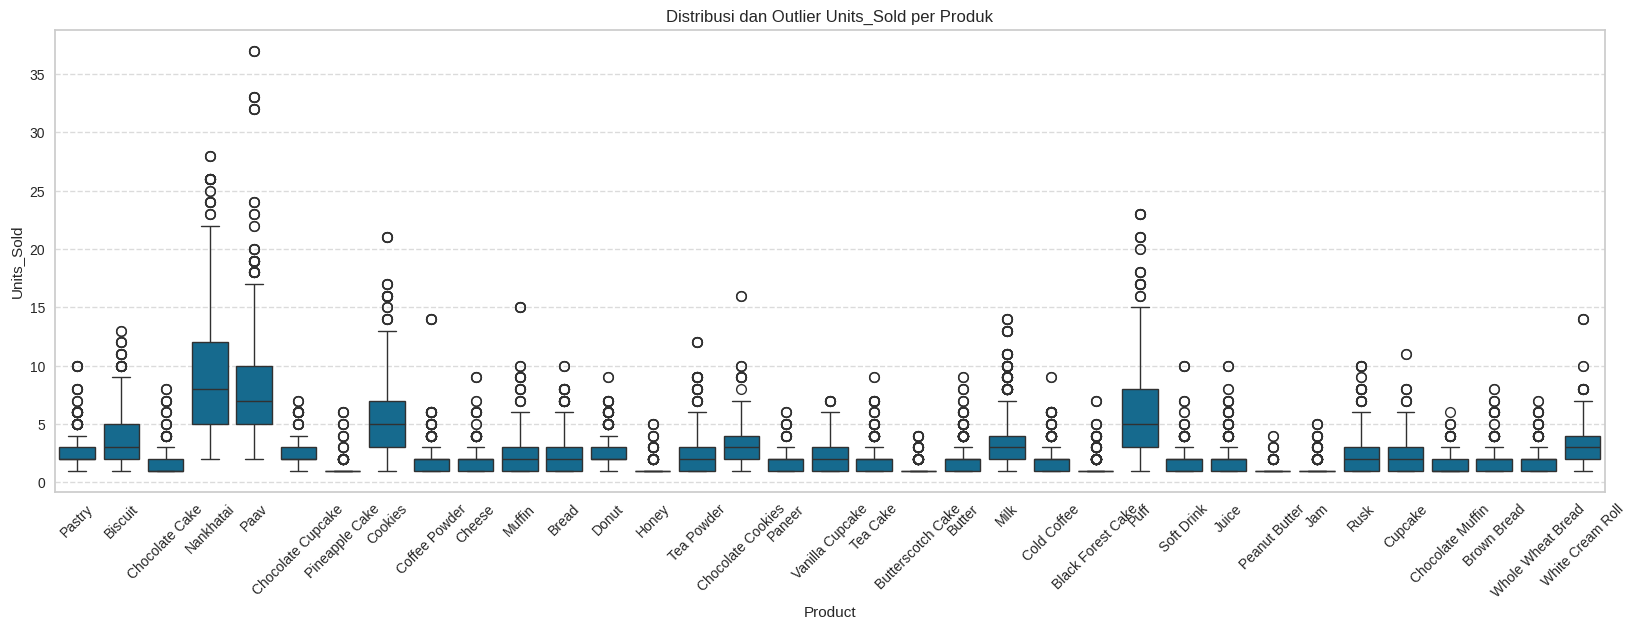

In [40]:
plt.figure(figsize=(20, 6))
sns.boxplot(x='Product', y='Units_Sold', data=df_bersih)
plt.title('Distribusi dan Outlier Units_Sold per Produk')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [47]:
def detect_iqr(df_bersih, column):
    Q1 = df_bersih[column].quantile(0.25)
    Q3 = df_bersih[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return df_bersih[(df_bersih[column] < lower_bound) | (df_bersih[column] > upper_bound)]

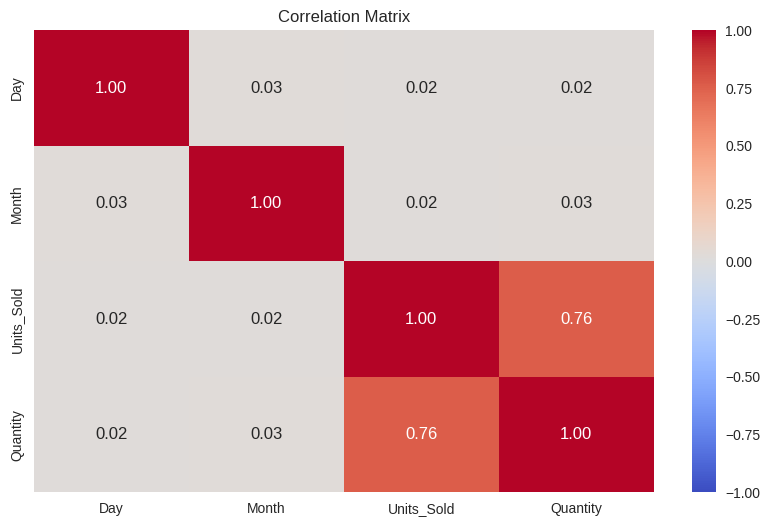

In [48]:
# Memilih kolom numerik
numerical_cols = df_bersih.select_dtypes(include=['number']).columns

### MULAI CODE ###

# Hitung matriks korelasi
correlation = df_bersih[numerical_cols].corr()

# Buat visualisasi heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(correlation,
               annot=True,
               cmap='coolwarm',
               fmt=".2f",
               vmin=-1,
               vmax=1)
plt.title('Correlation Matrix')
plt.show()


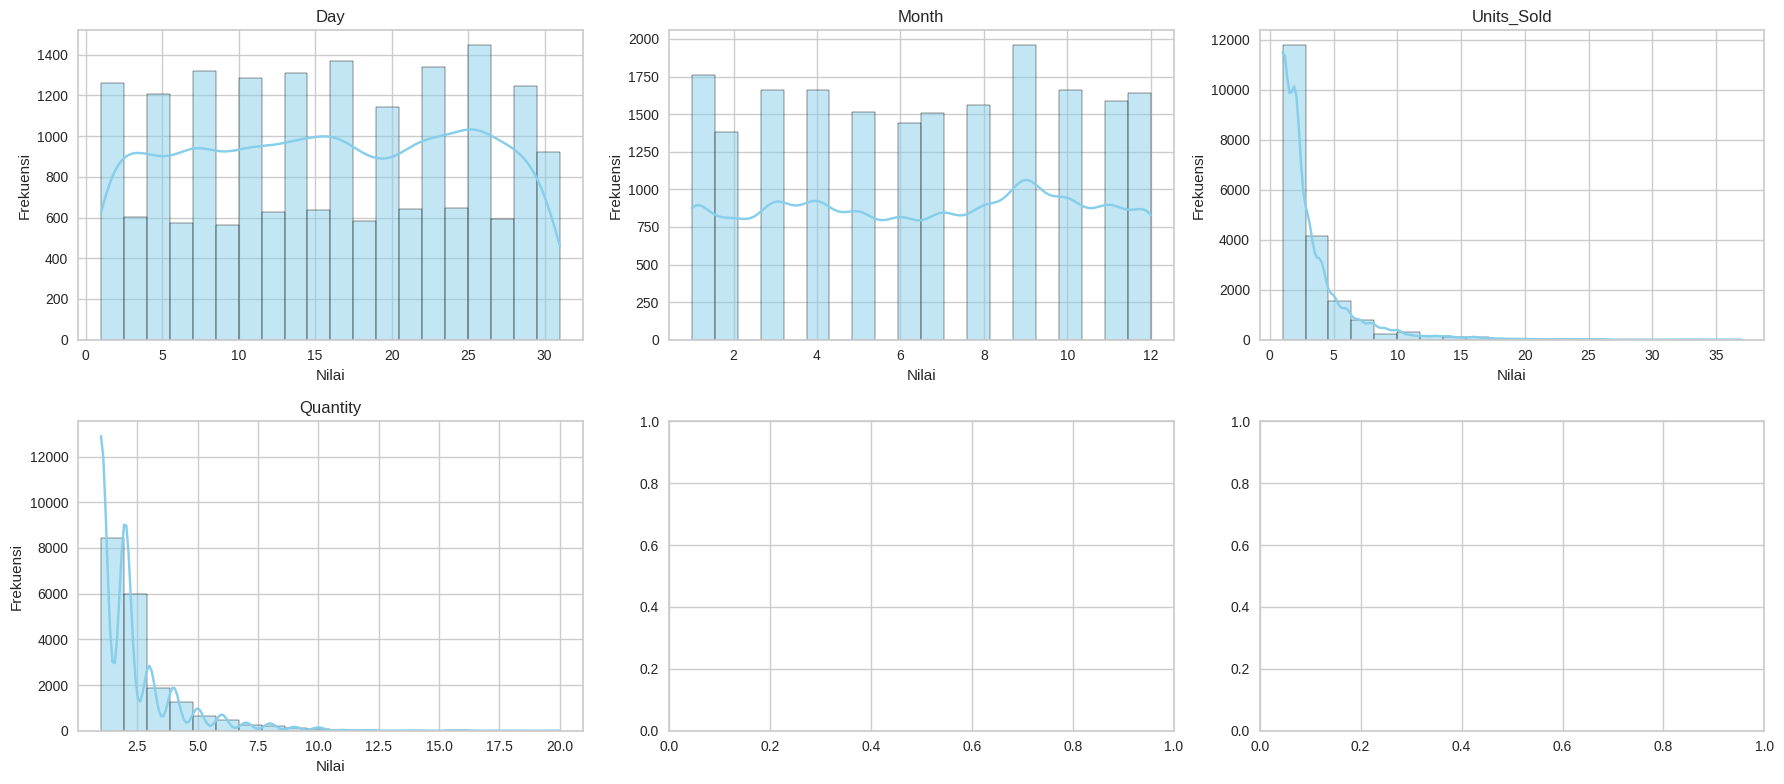

In [49]:
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
axes = axes.flatten()

for i, column in enumerate(numerical_cols):

    ### MULAI CODE ###

    # Tampilkan histogram dan pastikan plot ditempatkan di subplot (axes) yang benar
    sns.histplot(df_bersih[column], bins=20, kde=True, color='skyblue', ax=axes[i])

    # Atur judul dan label
    axes[i].set_title(column)
    axes[i].set_xlabel("Nilai")
    axes[i].set_ylabel("Frekuensi")

    ### SELESAI CODE ###

plt.tight_layout()
plt.show()

In [54]:
df_bersih.isnull().sum()

,0
Date,0
Day,0
Day_of_Week,0
Weekend,0
Month,0
Product,0
Units_Sold,0
Quantity,0


In [55]:



df_bersih.drop_duplicates(inplace=True)

In [56]:
df_bersih.duplicated().sum()

np.int64(0)

In [57]:
# Melakukan feature encoding menggunakan LabelEncoder() untuk fitur kategorikal.
# Pastikan kamu menggunakan function head setelah melalukan encoding.

### MULAI CODE ###

# Pilih semua kolom yang bertipe 'object' (kategorikal)
categorical_cols = list(df_bersih.select_dtypes(include=['object']).columns)

encoders = {}

# Loop melalui setiap kolom kategorikal
for column in categorical_cols:
    # Buat (instantiate) objek LabelEncoder
    label_encoder = LabelEncoder()

    # Terapkan (fit) encoder ke data dan sekaligus ubah (transform) data tersebut
    df_bersih[column] = label_encoder.fit_transform(df_bersih[column])

    # Simpan encoder
    encoders[column] = label_encoder

# Tampilkan 5 baris pertama untuk memverifikasi hasil encoding
df_bersih.head()


,Date,Day,Day_of_Week,Weekend,Month,Product,Units_Sold,Quantity
0,0,1,3,1,1,24,6,6
1,0,1,3,1,1,0,3,3
2,0,1,3,1,1,7,2,1
3,0,1,3,1,1,21,10,7
4,0,1,3,1,1,22,3,3


In [58]:
df_bersih.columns.tolist()

['Date',
 'Day',
 'Day_of_Week',
 'Weekend',
 'Month',
 'Product',
 'Units_Sold',
 'Quantity']

In [ ]:
# Contoh memilih kolom yang relevan saja
kolom_digunakan = ['Date', 'fitur_2', 'fitur_3', 'target']
df_bersih = df[kolom_digunakan]

In [ ]:
df = df.rename(columns={
    'Catagory': 'kategori',
    'Stock_Quantity': 'Jumlah_stok',
    'Reorder_Quantity': 'Jumlah_permintaan',
    'Sales_Volume': 'Jumlah_penjualan',
    'Expiration_Date': 'Tanggal_kadaluarsa',
    'Date_Recived': 'tanggal_diterima_pesanan',
    'Product_Name': 'nama_produk'

})

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 990 entries, 0 to 989
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   nama_produk         990 non-null    object
 1   kategori            989 non-null    object
 2   Jumlah_stok         990 non-null    int64 
 3   Jumlah_permintaan   990 non-null    int64 
 4   Date_Received       990 non-null    object
 5   Tanggal_kadaluarsa  990 non-null    object
 6   Jumlah_penjualan    990 non-null    int64 
dtypes: int64(3), object(4)
memory usage: 54.3+ KB


In [ ]:
df.describe()

,Jumlah_stok,Jumlah_permintaan,Jumlah_penjualan
count,990.000000,990.000000,990.000000
mean,55.609091,51.913131,58.925253
std,26.300775,29.521059,23.002318
min,10.000000,1.000000,20.000000
25%,33.000000,25.000000,39.000000
50%,56.000000,54.000000,58.000000
75%,79.000000,77.000000,78.000000
max,100.000000,100.000000,100.000000


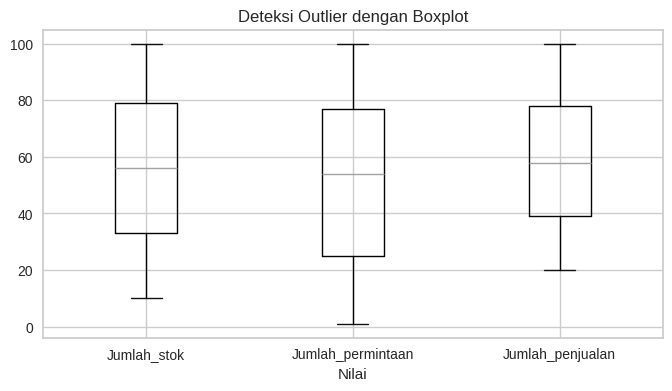

In [ ]:
plt.figure(figsize=(8, 4))
df.boxplot(column=['Jumlah_stok', 'Jumlah_permintaan','Jumlah_penjualan'])
plt.title('Deteksi Outlier dengan Boxplot')
plt.xlabel('Nilai')
plt.show()

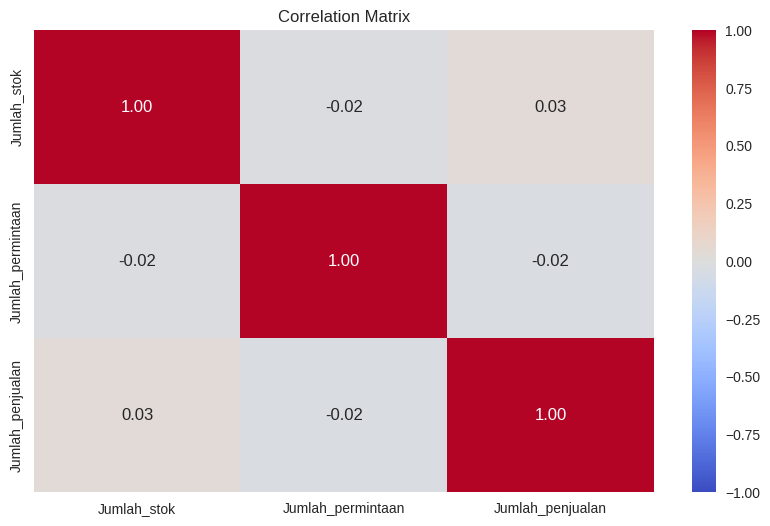

In [ ]:
# Menampilkan korelasi antar fitur (Opsional Skilled 1)

# Memilih kolom numerik
numerical_cols = df.select_dtypes(include=['number']).columns

### MULAI CODE ###

# Hitung matriks korelasi
correlation = df[numerical_cols].corr()

# Buat visualisasi heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(correlation,
               annot=True,
               cmap='coolwarm',
               fmt=".2f",
               vmin=-1,
               vmax=1)
plt.title('Correlation Matrix')
plt.show()

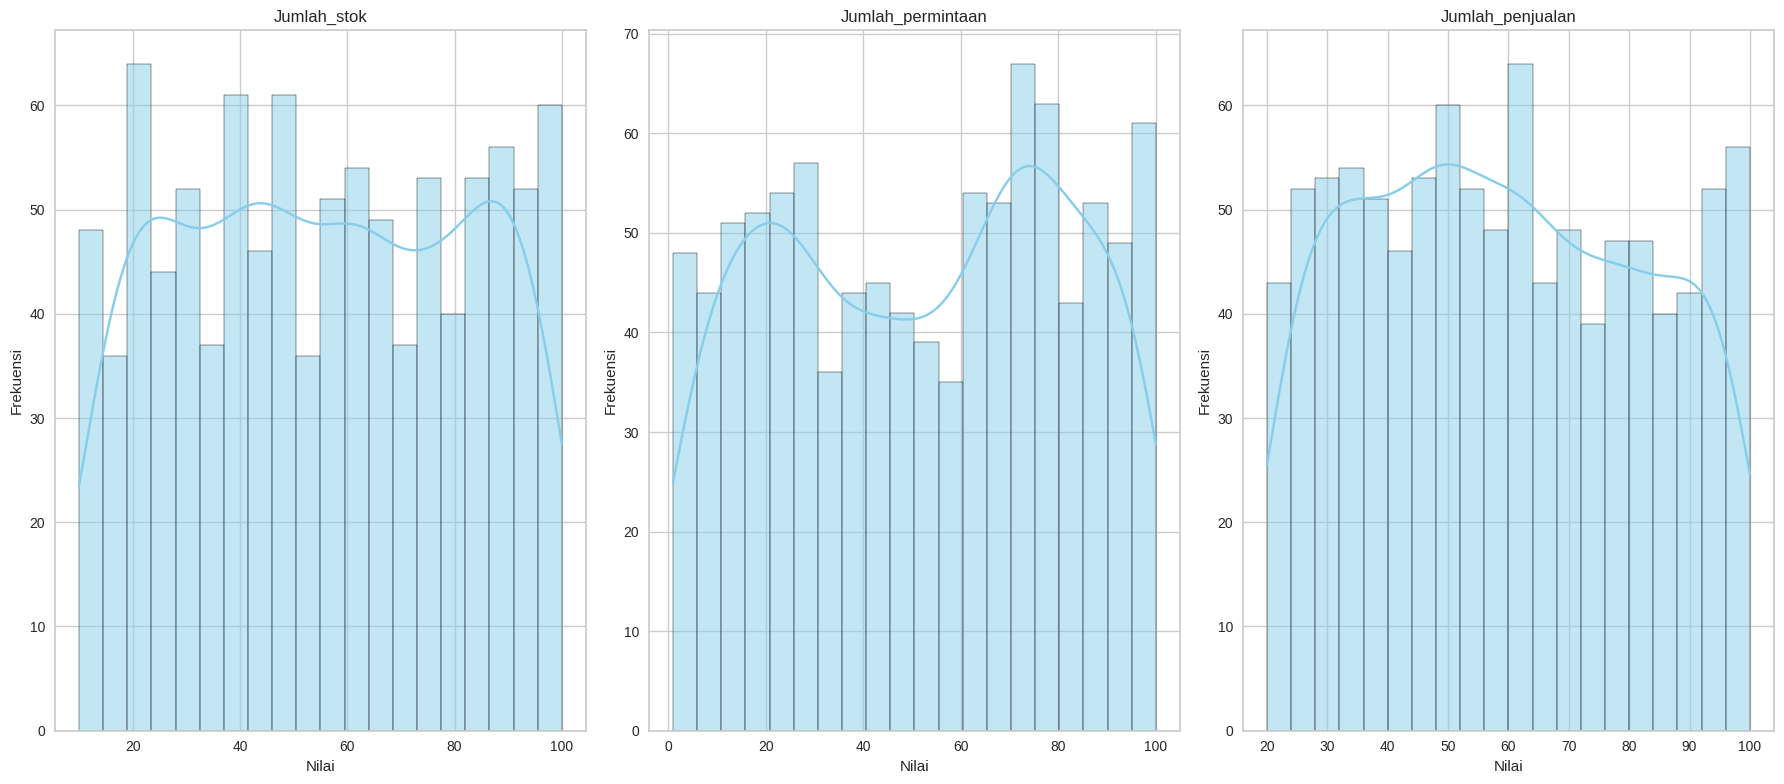

In [ ]:
# Menampilkan histogram untuk semua kolom numerik (Opsional Skilled 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 8))
axes = axes.flatten()

for i, column in enumerate(numerical_cols):

    ### MULAI CODE ###

    # Tampilkan histogram dan pastikan plot ditempatkan di subplot (axes) yang benar
    sns.histplot(df[column], bins=20, kde=True, color='skyblue', ax=axes[i])

    # Atur judul dan label
    axes[i].set_title(column)
    axes[i].set_xlabel("Nilai")
    axes[i].set_ylabel("Frekuensi")

    ### SELESAI CODE ###

plt.tight_layout()
plt.show()

/tmp/ipykernel_2364/2168121640.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=cat_stock, x='Jumlah_stok', y='kategori', palette='Blues_r')


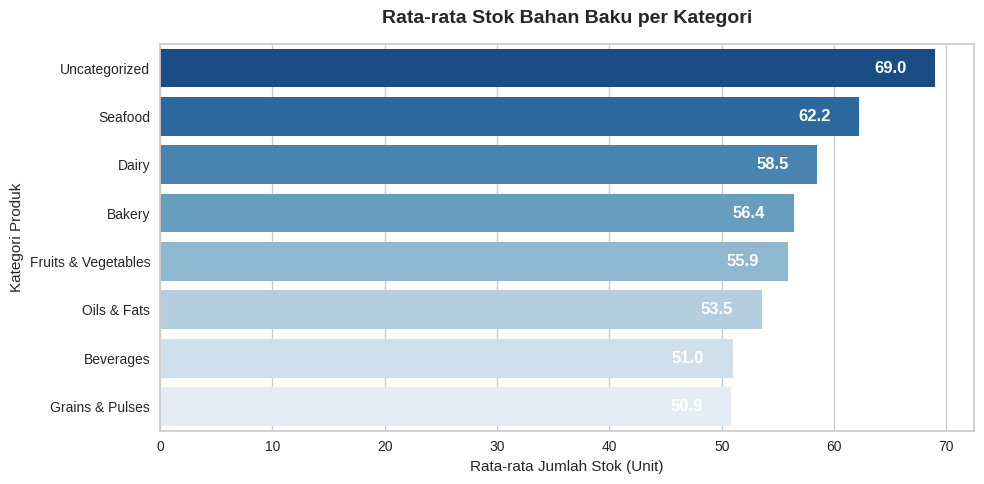

In [ ]:

df['kategori'] = df['kategori'].fillna('Uncategorized')

plt.figure(figsize=(10, 5))
cat_stock = df.groupby('kategori')['Jumlah_stok'].mean().sort_values(ascending=False).reset_index()

ax = sns.barplot(data=cat_stock, x='Jumlah_stok', y='kategori', palette='Blues_r')
plt.title('Rata-rata Stok Bahan Baku per Kategori', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Rata-rata Jumlah Stok (Unit)')
plt.ylabel('Kategori Produk')

# Menambahkan label angka
for p in ax.patches:
    width = p.get_width()
    ax.annotate(f'{width:.1f}', (width - 4, p.get_y() + p.get_height() / 2.),
                ha='center', va='center', color='white', fontweight='bold')

plt.tight_layout()
plt.show()

/tmp/ipykernel_2364/2644336700.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='Needs_Restock', palette=['#2ecc71', '#e74c3c'])


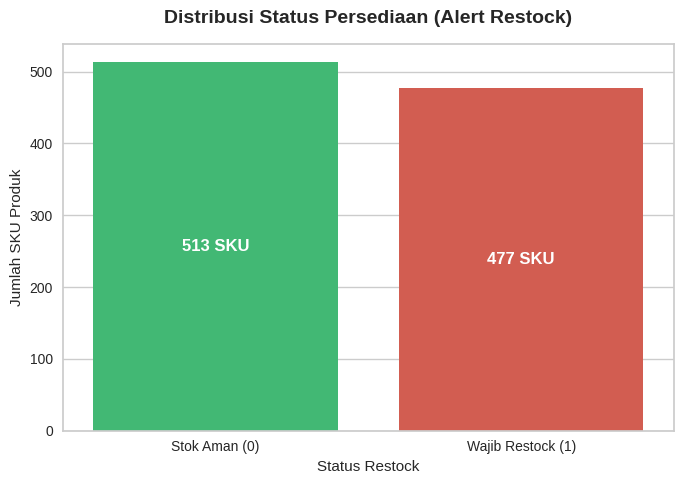

In [ ]:
# Membuat variabel biner restock
df['Needs_Restock'] = (df['Jumlah_stok'] <= df['Jumlah_permintaan']).astype(int)

plt.figure(figsize=(7, 5))
ax = sns.countplot(data=df, x='Needs_Restock', palette=['#2ecc71', '#e74c3c'])
plt.title('Distribusi Status Persediaan (Alert Restock)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Status Restock')
plt.ylabel('Jumlah SKU Produk')
plt.xticks([0, 1], ['Stok Aman (0)', 'Wajib Restock (1)'])

for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{int(height)} SKU', (p.get_x() + p.get_width() / 2., height / 2),
                ha='center', va='center', color='white', fontweight='bold', fontsize=12)

plt.tight_layout()
plt.show()